
![](https://raw.githubusercontent.com/wateraccounting/WaPORMOOC/main/images/banner_notebooks_WaPOR4Global.png)

[![](https://raw.githubusercontent.com//wateraccounting/WaPORMOOC/main/images/colab-badge.png)](https://colab.research.google.com/github/wateraccounting/WaPOR4Global/blob/main/2_Long_Time_Series_Analyses/Notebook_2.1_Iraq_Timeseries_Analyses.ipynb?target="_blank")


<div style="text-align:center;margin-top:15px;">
<h3 style="margin-bottom:5px;">
<b>Characterising Iraq's Climate</b>
</h3>

<p style="margin-top:5px;">
<b>Notebook 2.1:</b> Long time series analyses  &nbsp; | &nbsp;<b>Estimated time:</b> 4 hours &nbsp; | &nbsp;
<b>Instructor:</b> Dr. Ahmed Elnaggar
</p>
</div>

---

### 📚 Course Information

| Item | Description |
|------|-------------|
| **Course** | MOOC — Global Challenges for Water in Agriculture |
| **Module** | 3.1: Long Time Series Analyses |
| **Focus** | Spatial and temporal variability of Rainfall & Reference ET |
| **Region** | Iraq — 18 Governorates |
| **Data** | Monthly observations (1980–present) |

---

### 🎯 Learning Objectives

By the end of this notebook, you will be able to:

1. **Characterize** the climatological patterns of rainfall and reference ET across Iraq
2. **Identify** drought and wet anomalies at the governorate level
3. **Compute** aridity indices to assess regional water stress

---


> 💡 **Key Questions:** *What is the spatio-temporal variability of the climate in Iraq? How is the climate changing over time?*

---

### 📖 Table of Contents

1. Setup & Data Loading
2. Temporal Patterns
3. Descriptive Statistics
4. Monthly Variability
5. Trend Analyses
6. Anomalies
7. Aridity Index
8. Visualising results

---

## 1. Setting up the environment & load data for analyses
We start with setting up the environment and install specific packages.
### Required Packages

We use standard Python data-science libraries as well as a specific package `pymannkendall` to calculate trends using the Mann-Kendall trend test.

In [1]:
# =============================================================================
# INSTALL & IMPORT PACKAGES
# =============================================================================

!pip install numpy pandas matplotlib seaborn scipy pymannkendall --quiet

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import pymannkendall as mk
#from scipy import stats
import os
import warnings
from datetime import datetime
from pathlib import Path

print(f"\n\u2705 Setup complete \u2014 Pandas {pd.__version__}, NumPy {np.__version__}")
print(f"\U0001f4c5 Analysis date: {datetime.now().strftime('%Y-%m-%d')}")


✅ Setup complete — Pandas 2.2.3, NumPy 2.4.6
📅 Analysis date: 2026-11-12


### Data Files
Create folders for where to upload the input data and where to store the results.


In [2]:
# =============================================================================
# CREATE INPUT AND OUTPUT FOLDERS
# =============================================================================

data_folder = 'data'
os.makedirs(data_folder, exist_ok=True)

output_folder = 'output_data'
os.makedirs(output_folder, exist_ok=True)

### Upload the data files
Place the following data* files in the new folder called `data/` (source of data: AgERA5 for the period 1980-2025):

| File | Description |
|------|-------------|
| `irq_admin1_AgERA5-PCP-M_mm.csv` | Monthly rainfall (mm/month) for 18 governorates of Iraq|
| `irq_admin1_AgERA5-RET-M_mm.csv` | Monthly reference ET (mm/month) for 18 governorates of Iraq |


**Expected CSV format:** First column = date (`DD/MM/YYYY`), remaining columns = governorate names.

---

*Instructions on how to download the required data is provided in this [Notebook](https://github.com/wateraccounting/WaPOR4Global/blob/3ad5ff1574e2d57b0100e814bb5b016b56d26c96/1.%20Accessing%20WaPOR%20data/Notebook1_Accessing_WaPOR_data.ipynb).

In [6]:
# Upload data.
from google.colab import files
uploaded = files.upload()

# Save each file to the destination folder
for filename, content in uploaded.items():
    dest_path = f'/content/data/{filename}'
    with open(dest_path, 'wb') as f:
        f.write(content)
    print(f" Saved: {dest_path}")

Saving irq_admin1_AgERA5-RET-M_mm.csv to irq_admin1_AgERA5-RET-M_mm.csv
Saving irq_admin1_AgERA5-PCP-M_mm.csv to irq_admin1_AgERA5-PCP-M_mm.csv
 Saved: /content/data/irq_admin1_AgERA5-RET-M_mm.csv
 Saved: /content/data/irq_admin1_AgERA5-PCP-M_mm.csv


### Read and define data files
The `load_governorate_data` function is run using the following script for each data file. For this exercise you read monthly rainfall and reference ET data from AgERA5 for the period 1980-2025.

Check if for each data set you have data for the entire period.


In [51]:
# =============================================================================
# READ DATA FILES
# =============================================================================


def load_governorate_data(filepath, name='dataset'):
    """
    Load monthly governorate-level data from CSV.
    Expects: first column = date, remaining columns = governorates.
    """
    # Fix: Changed delimiter from ';' to ','
    df = pd.read_csv(filepath, delimiter=',')
    date_col = df.columns[0]

    # Parse dates (try multiple formats)
    for fmt in ['%d/%m/%Y', '%m/%d/%Y', '%Y-%m-%d', '%Y/%m/%d']:
      try:
          df[date_col] = pd.to_datetime(df[date_col], format=fmt)
          break # Exit loop if parsing successful
      except ValueError:
          continue
    else: # This block executes if the loop completes without a 'break'
        # If no format worked, try mixed inference
        df[date_col] = pd.to_datetime(df[date_col], errors='coerce', dayfirst=False, yearfirst=True)


    df.set_index(date_col, inplace=True)
    df.index.name = 'date'
    df = df.sort_index()

    # Ensure numeric
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    print(f"\U0001f4c4 {name}: {df.shape[0]} months × {df.shape[1]} governorates")
    print(f"   Period: {df.index.min().strftime('%b %Y')} — {df.index.max().strftime('%b %Y')}")
    return df

# --- Load Rainfall ---
rainfall_file = '/content/data/irq_admin1_AgERA5-PCP-M_mm.csv'
df_rain = load_governorate_data(rainfall_file, name='Rainfall')

# --- Load Reference ET ---
ret_file = '/content/data/irq_admin1_AgERA5-RET-M_mm.csv'
df_ret = load_governorate_data(ret_file, name='Reference ET')

# --- Governorate list ---
governorates = df_rain.columns.tolist()
n_gov = len(governorates)
print(f"\n\U0001f4cd {n_gov} governorates detected: {governorates}")

📄 Rainfall: 552 months × 18 governorates
   Period: Jan 1980 — Dec 2025
📄 Reference ET: 552 months × 18 governorates
   Period: Jan 1980 — Dec 2025

📍 18 governorates detected: ['Al-Anbar', 'Al-Basrah', 'Al-Muthanna', 'Al-Najaf', 'Al-Qadissiya', 'Al-Sulaymaniyah', 'Babil', 'Baghdad', 'Diyala', 'Duhok', 'Erbil', 'Kerbala', 'Kirkuk', 'Maysan', 'Ninewa', 'Salah Al-Din', 'Thi Qar', 'Wassit']


### Inspect the data

If all data is loaded, now lets have a look at the data! Inspect if the data contains information for all the 18 governorates and the period 1980-2025.

The precipitation data file is loaded into the script as `df_rain/`. To view the content of the file, you can use the `display` function.



In [8]:
# =============================================================================
# DATA INSPECTION
# =============================================================================

print("RAINFALL DATA - First 12 Months")
display(df_rain.head(12))


RAINFALL DATA - First 12 Months


,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
date,,,,,,,,,,,,,,,,,,
1980-01-01,11.63,19.76,11.80,7.15,9.92,106.33,11.10,14.34,35.04,93.52,91.91,8.19,35.05,36.22,34.06,16.70,17.18,26.79
1980-02-01,56.31,80.02,78.00,59.85,64.76,146.25,72.09,74.64,92.57,118.25,117.30,76.95,88.31,130.04,86.88,73.87,94.04,87.87
1980-03-01,11.83,16.79,10.32,14.31,23.77,167.32,14.14,16.86,63.85,230.16,178.85,9.76,74.90,46.09,88.12,26.04,21.89,39.52
1980-04-01,12.16,2.03,2.11,3.30,4.98,122.62,7.36,13.85,21.50,239.74,165.96,6.06,51.55,4.36,92.96,22.47,4.12,7.77
1980-05-01,0.42,0.27,0.62,0.26,1.18,17.25,0.19,0.38,1.88,61.06,24.54,0.13,2.78,2.10,8.69,1.26,1.35,2.11
1980-06-01,0.00,0.00,0.00,0.00,0.00,2.16,0.00,0.00,0.01,4.31,3.07,0.00,0.29,0.00,0.81,0.06,0.00,0.00
1980-07-01,0.00,0.03,0.00,0.00,0.00,0.10,0.01,0.00,0.00,1.80,1.19,0.00,0.00,0.01,0.04,0.00,0.02,0.00
1980-08-01,0.00,0.00,0.00,0.00,0.00,0.83,0.00,0.00,0.00,1.13,1.16,0.00,0.04,0.00,0.02,0.00,0.00,0.00
1980-09-01,0.03,0.00,0.00,0.00,0.00,0.22,0.00,0.00,0.01,1.17,0.74,0.00,0.07,0.00,0.06,0.06,0.00,0.00


**📊 Exercise**: Can you also inspect the Reference ET data file?

<details>
<summary style="cursor:pointer; color:#555; font-size:14px; margin-top:12px;"><b>HINT</b></summary>
<br>

Inspect the code in the previous cell and identify the name of the dataframe which contains the reference ET data.
</details>

In [10]:
import pandas as pd

# Load Reference ET data
file_path = "/content/data/irq_admin1_AgERA5-RET-M_mm.csv"

df_ret = pd.read_csv(file_path, parse_dates=["Date"], dayfirst=True)

# Inspect dataset
print("=" * 60)
print("REFERENCE EVAPOTRANSPIRATION DATA INSPECTION")
print("=" * 60)

print("\nDataset dimensions:")
print(df_ret.shape)

print("\nColumn names:")
print(df_ret.columns.tolist())

print("\nFirst five records:")
display(df_ret.head())

print("\nLast five records:")
display(df_ret.tail())

print("\nData types:")
print(df_ret.dtypes)

print("\nDate range:")
print("Start:", df_ret["Date"].min())
print("End:", df_ret["Date"].max())

print("\nMissing values:")
print(df_ret.isnull().sum())

print("\nDescriptive statistics:")
display(df_ret.describe().round(2))

REFERENCE EVAPOTRANSPIRATION DATA INSPECTION

Dataset dimensions:
(552, 19)

Column names:
['Date', 'Al-Anbar', 'Al-Basrah', 'Al-Muthanna', 'Al-Najaf', 'Al-Qadissiya', 'Al-Sulaymaniyah', 'Babil', 'Baghdad', 'Diyala', 'Duhok', 'Erbil', 'Kerbala', 'Kirkuk', 'Maysan', 'Ninewa', 'Salah Al-Din', 'Thi Qar', 'Wassit']

First five records:


,Date,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
0,1980-01-01,53.40,64.78,72.10,70.36,63.68,27.46,58.78,48.64,40.34,23.05,26.40,59.08,32.97,47.74,29.89,39.55,59.75,48.52
1,1980-02-01,61.25,73.41,77.87,76.62,72.15,37.54,67.33,58.25,52.41,33.82,37.75,62.57,46.47,59.68,42.07,52.45,70.50,61.06
2,1980-03-01,130.02,150.11,163.58,159.32,152.04,70.52,145.08,126.98,108.38,56.90,64.90,136.91,86.07,125.50,76.50,109.10,146.37,128.46
3,1980-04-01,193.02,236.72,235.22,217.49,230.16,114.86,217.11,199.88,190.89,90.63,106.75,201.72,149.27,220.07,132.42,179.84,238.63,225.83
4,1980-05-01,263.01,316.33,295.72,283.68,300.49,177.13,284.01,267.21,264.95,147.54,169.51,270.65,224.78,312.70,216.27,260.81,315.09,304.38



Last five records:


,Date,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
547,2025-08-01,313.10,376.55,370.30,322.76,395.88,225.30,367.03,344.31,348.09,205.26,224.05,336.33,287.64,384.23,294.80,345.23,411.35,412.77
548,2025-09-01,225.43,302.73,256.76,233.26,267.25,167.53,244.24,227.65,240.28,146.33,162.16,226.21,198.03,321.03,200.87,226.98,299.45,296.18
549,2025-10-01,168.61,229.50,204.04,187.74,201.04,116.82,184.78,170.95,180.45,96.78,111.06,174.78,144.29,229.75,141.11,167.94,222.94,219.54
550,2025-11-01,110.00,135.19,136.26,120.28,129.31,67.71,118.96,105.33,107.77,55.90,63.21,111.90,86.38,127.69,80.92,102.09,132.74,127.79
551,2025-12-01,57.63,74.60,82.73,74.21,73.37,37.57,67.90,58.91,61.43,28.03,33.01,65.86,48.42,64.02,38.24,53.54,73.34,68.56



Data types:
Date               datetime64[ns]
Al-Anbar                  float64
Al-Basrah                 float64
Al-Muthanna               float64
Al-Najaf                  float64
Al-Qadissiya              float64
Al-Sulaymaniyah           float64
Babil                     float64
Baghdad                   float64
Diyala                    float64
Duhok                     float64
Erbil                     float64
Kerbala                   float64
Kirkuk                    float64
Maysan                    float64
Ninewa                    float64
Salah Al-Din              float64
Thi Qar                   float64
Wassit                    float64
dtype: object

Date range:
Start: 1980-01-01 00:00:00
End: 2025-12-01 00:00:00

Missing values:
Date               0
Al-Anbar           0
Al-Basrah          0
Al-Muthanna        0
Al-Najaf           0
Al-Qadissiya       0
Al-Sulaymaniyah    0
Babil              0
Baghdad            0
Diyala             0
Duhok              0
Erbil         

,Date,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
count,552,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00,552.00
mean,2002-12-16 05:13:02.608695680,183.45,231.12,216.42,200.84,221.11,124.80,205.10,188.93,188.73,105.90,120.59,193.11,156.27,229.53,152.12,182.39,232.83,223.61
min,1980-01-01 00:00:00,40.60,52.41,55.49,52.16,50.68,27.25,47.57,38.61,36.07,21.28,24.42,46.80,29.91,42.90,22.66,30.99,49.38,42.07
25%,1991-06-23 12:00:00,80.66,110.14,107.98,97.89,101.97,48.24,93.63,81.60,79.68,38.88,45.42,87.20,62.20,97.82,55.72,72.25,108.05,95.64
50%,2002-12-16 12:00:00,173.91,219.74,210.29,199.48,209.72,115.12,193.39,177.75,181.92,92.81,109.52,181.25,145.93,213.76,136.30,169.50,219.19,212.54
75%,2014-06-08 12:00:00,286.92,343.79,321.56,297.39,335.22,202.46,313.52,297.12,293.62,171.84,196.29,300.79,252.36,351.68,252.56,295.69,345.60,340.37
max,2025-12-01 00:00:00,368.43,459.08,401.23,373.87,424.00,248.59,393.12,368.36,374.83,219.76,247.39,374.42,315.62,488.74,320.08,369.89,464.60,456.43
std,NaN,99.95,121.50,105.58,98.11,115.74,73.89,108.72,104.91,107.70,66.13,73.29,103.12,92.08,133.41,96.12,109.43,125.26,126.65


In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Correct file paths
pcp_path = "/content/data/irq_admin1_AgERA5-PCP-M_mm.csv"
ret_path = "/content/data/irq_admin1_AgERA5-RET-M_mm.csv"

# Load datasets
df_pcp = pd.read_csv(pcp_path)
df_ret = pd.read_csv(ret_path)

# Inspect column names
print("PRECIPITATION COLUMNS:")
print(df_pcp.columns.tolist())

print("\nRET COLUMNS:")
print(df_ret.columns.tolist())

print("\nPRECIPITATION SHAPE:", df_pcp.shape)
print("RET SHAPE:", df_ret.shape)

# Display first five rows
display(df_pcp.head())
display(df_ret.head())

PRECIPITATION COLUMNS:
['Date', 'Al-Anbar', 'Al-Basrah', 'Al-Muthanna', 'Al-Najaf', 'Al-Qadissiya', 'Al-Sulaymaniyah', 'Babil', 'Baghdad', 'Diyala', 'Duhok', 'Erbil', 'Kerbala', 'Kirkuk', 'Maysan', 'Ninewa', 'Salah Al-Din', 'Thi Qar', 'Wassit']

RET COLUMNS:
['Date', 'Al-Anbar', 'Al-Basrah', 'Al-Muthanna', 'Al-Najaf', 'Al-Qadissiya', 'Al-Sulaymaniyah', 'Babil', 'Baghdad', 'Diyala', 'Duhok', 'Erbil', 'Kerbala', 'Kirkuk', 'Maysan', 'Ninewa', 'Salah Al-Din', 'Thi Qar', 'Wassit']

PRECIPITATION SHAPE: (552, 19)
RET SHAPE: (552, 19)


,Date,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
0,01/01/1980,11.63,19.76,11.80,7.15,9.92,106.33,11.10,14.34,35.04,93.52,91.91,8.19,35.05,36.22,34.06,16.70,17.18,26.79
1,01/02/1980,56.31,80.02,78.00,59.85,64.76,146.25,72.09,74.64,92.57,118.25,117.30,76.95,88.31,130.04,86.88,73.87,94.04,87.87
2,01/03/1980,11.83,16.79,10.32,14.31,23.77,167.32,14.14,16.86,63.85,230.16,178.85,9.76,74.90,46.09,88.12,26.04,21.89,39.52
3,01/04/1980,12.16,2.03,2.11,3.30,4.98,122.62,7.36,13.85,21.50,239.74,165.96,6.06,51.55,4.36,92.96,22.47,4.12,7.77
4,01/05/1980,0.42,0.27,0.62,0.26,1.18,17.25,0.19,0.38,1.88,61.06,24.54,0.13,2.78,2.10,8.69,1.26,1.35,2.11


,Date,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
0,01/01/1980,53.40,64.78,72.10,70.36,63.68,27.46,58.78,48.64,40.34,23.05,26.40,59.08,32.97,47.74,29.89,39.55,59.75,48.52
1,01/02/1980,61.25,73.41,77.87,76.62,72.15,37.54,67.33,58.25,52.41,33.82,37.75,62.57,46.47,59.68,42.07,52.45,70.50,61.06
2,01/03/1980,130.02,150.11,163.58,159.32,152.04,70.52,145.08,126.98,108.38,56.90,64.90,136.91,86.07,125.50,76.50,109.10,146.37,128.46
3,01/04/1980,193.02,236.72,235.22,217.49,230.16,114.86,217.11,199.88,190.89,90.63,106.75,201.72,149.27,220.07,132.42,179.84,238.63,225.83
4,01/05/1980,263.01,316.33,295.72,283.68,300.49,177.13,284.01,267.21,264.95,147.54,169.51,270.65,224.78,312.70,216.27,260.81,315.09,304.38


In [54]:
# Convert dates using day-first format
df_pcp["Date"] = pd.to_datetime(
    df_pcp["Date"], dayfirst=True
)

df_ret["Date"] = pd.to_datetime(
    df_ret["Date"], dayfirst=True
)

# Identify governorate columns
governorates = [
    col for col in df_pcp.columns
    if col != "Date"
]

# Extract calendar month
df_pcp["Month"] = df_pcp["Date"].dt.month
df_ret["Month"] = df_ret["Date"].dt.month

# Calculate long-term monthly averages
pcp_monthly = df_pcp.groupby("Month")[governorates].mean()
ret_monthly = df_ret.groupby("Month")[governorates].mean()

# Calculate mean across all 18 governorates
pcp_mean = pcp_monthly.mean(axis=1)
ret_mean = ret_monthly.mean(axis=1)

print("Monthly climatology calculated successfully.")

print("\nPrecipitation:")
print(pcp_mean.round(2))

print("\nReference Evapotranspiration:")
print(ret_mean.round(2))

Monthly climatology calculated successfully.

Precipitation:
Month
1     47.63
2     44.16
3     47.53
4     31.59
5     12.68
6      0.81
7      0.20
8      0.21
9      0.66
10    13.33
11    38.63
12    44.47
dtype: float64

Reference Evapotranspiration:
Month
1      54.35
2      75.45
3     132.34
4     188.94
5     261.01
6     318.95
7     343.38
8     313.43
9     237.70
10    165.78
11     89.13
12     57.45
dtype: float64


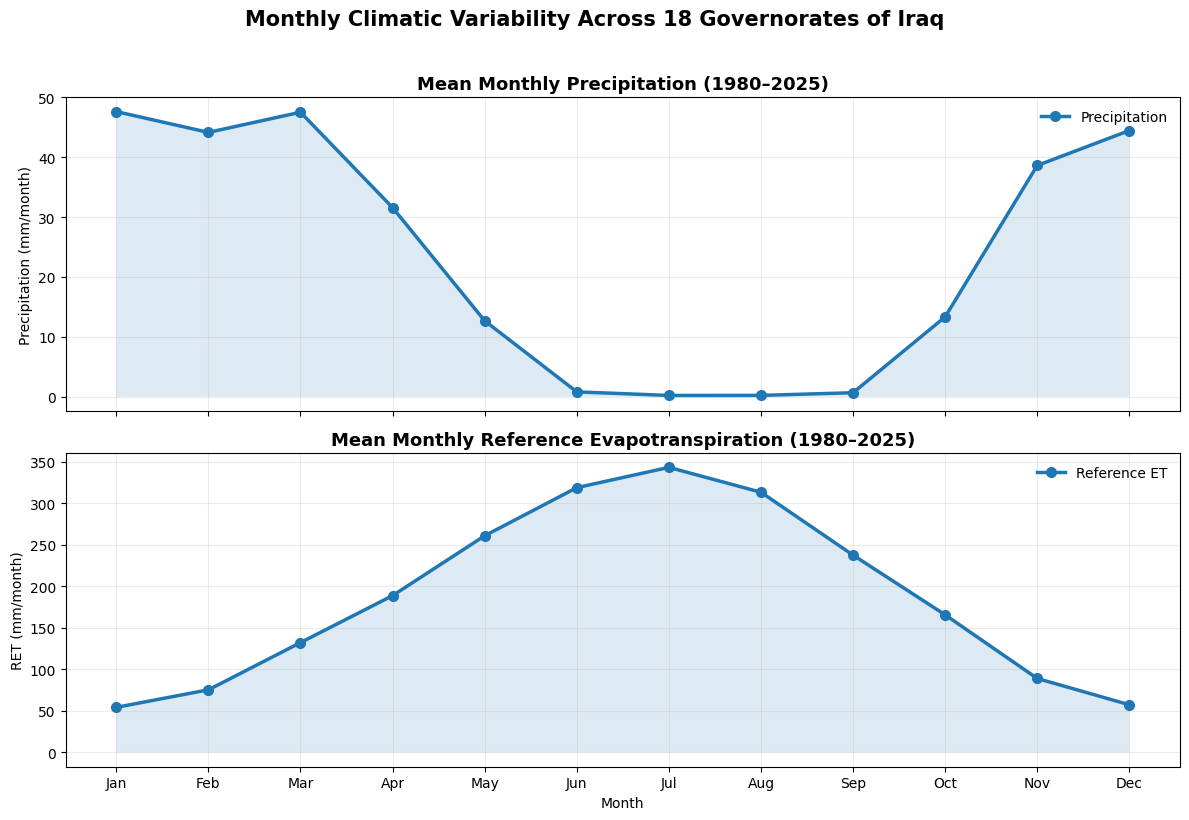

In [55]:
import matplotlib.pyplot as plt
import numpy as np

months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True
)

# Precipitation
axes[0].plot(
    months,
    pcp_mean.values,
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Precipitation"
)

axes[0].fill_between(
    months,
    pcp_mean.values,
    alpha=0.15
)

axes[0].set_title(
    "Mean Monthly Precipitation (1980–2025)",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel("Precipitation (mm/month)")
axes[0].grid(alpha=0.25)
axes[0].legend(frameon=False)

# Reference evapotranspiration
axes[1].plot(
    months,
    ret_mean.values,
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Reference ET"
)

axes[1].fill_between(
    months,
    ret_mean.values,
    alpha=0.15
)

axes[1].set_title(
    "Mean Monthly Reference Evapotranspiration (1980–2025)",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_ylabel("RET (mm/month)")
axes[1].set_xlabel("Month")
axes[1].grid(alpha=0.25)
axes[1].legend(frameon=False)

fig.suptitle(
    "Monthly Climatic Variability Across 18 Governorates of Iraq",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    "/content/Iraq_Monthly_PCP_RET_1980_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [57]:
from google.colab import files

# Download the first image
files.download("/content/Iraq_Monthly_PCP_RET_1980_2025.png")

# Download the second image
files.download("/content/Iraq_PCP_RET_Comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

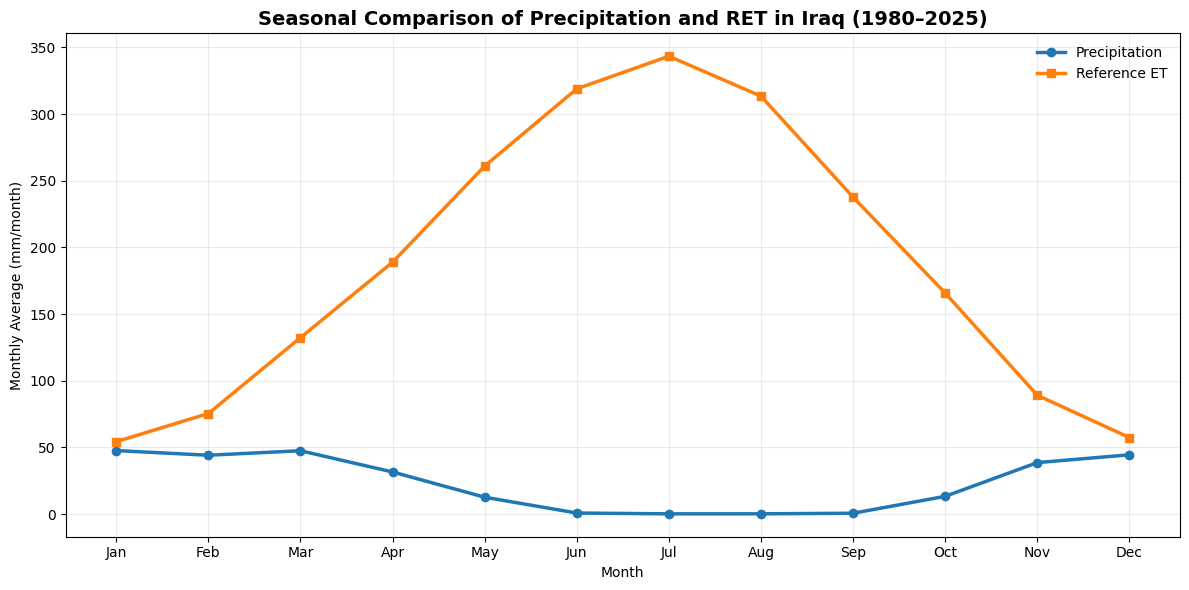

In [56]:
plt.figure(figsize=(12, 6))

plt.plot(
    months, pcp_mean.values,
    marker="o", linewidth=2.5,
    label="Precipitation"
)

plt.plot(
    months, ret_mean.values,
    marker="s", linewidth=2.5,
    label="Reference ET"
)

plt.title(
    "Seasonal Comparison of Precipitation and RET in Iraq (1980–2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Monthly Average (mm/month)")
plt.grid(alpha=0.25)
plt.legend(frameon=False)
plt.tight_layout()

plt.savefig(
    "/content/Iraq_PCP_RET_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Quick check for completeness of the rainfall data

The following cell will check if the data has any missing values.



In [11]:
# =============================================================================
# CHECK DATA FOR COMPLETENESS
# =============================================================================

print("\n\U0001f4ca Data Completeness:")
rain_missing = df_rain.isnull().sum()

if rain_missing.sum() == 0:
    print("   Rainfall:     \u2705 No missing values")
else:
    print(f"   Rainfall:     \u26a0\ufe0f {rain_missing.sum()} missing values")
    print(rain_missing[rain_missing > 0])


📊 Data Completeness:
   Rainfall:     ✅ No missing values


**📊 Exercise:** Can you check if the Reference ET data is also complete?

In [ ]:
# =============================================================================
# CHECK DATA FOR COMPLETENESS
# =============================================================================


---

## 2. Temporal Patterns

We start with plotting the raw time series using the function `.plot`. Run the cell below to visualise the monthly rainfall for all governorates.



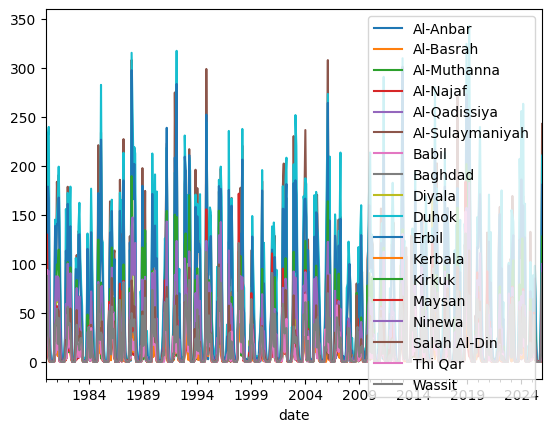

In [12]:
# =============================================================================
# RAINFALL TIME SERIES - ALL GOVERNORATES IN ONE GRAPH
# =============================================================================

df_rain.plot();


<Figure size 1400x700 with 0 Axes>

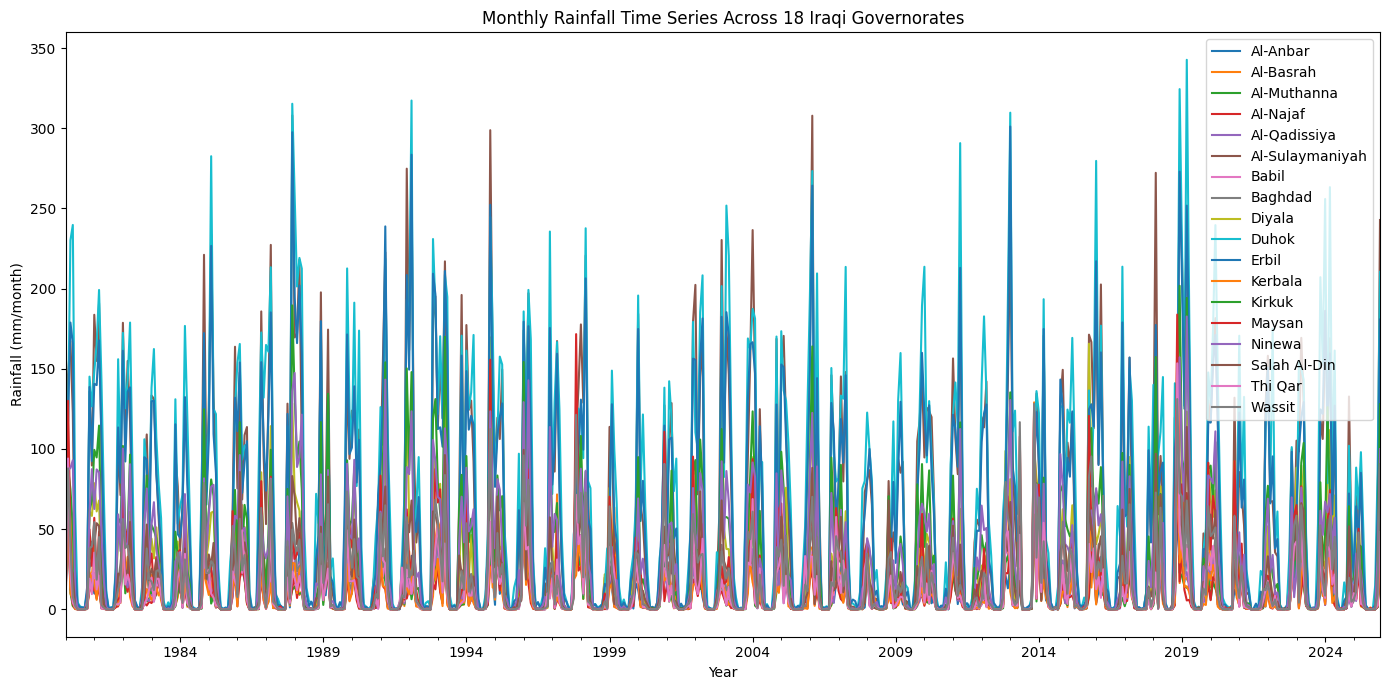

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
from google.colab import files

# Save the graph
plt.figure(figsize=(14, 7))
df_rain.plot(figsize=(14, 7))

plt.title("Monthly Rainfall Time Series Across 18 Iraqi Governorates")
plt.xlabel("Year")
plt.ylabel("Rainfall (mm/month)")
plt.tight_layout()

plt.savefig(
    "/content/Iraq_Rainfall_Time_Series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Download the image
files.download("/content/Iraq_Rainfall_Time_Series.png")

**📊Exercise:** update the code to visualise the Reference ET data as well.


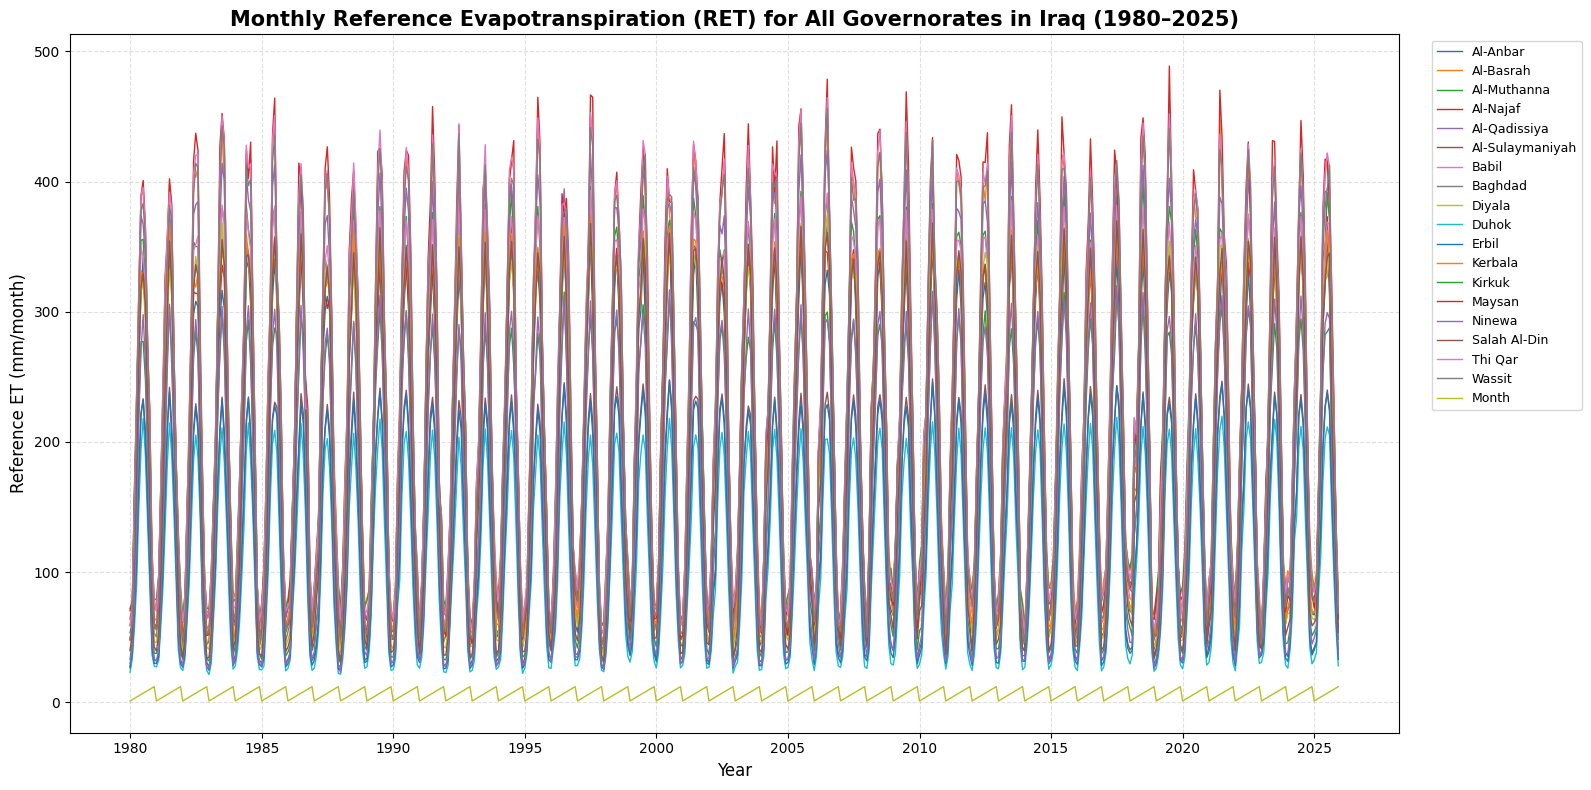

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
# ============================================================
# REFERENCE ET TIME SERIES - ALL GOVERNORATES IN ONE GRAPH
# WITH HIGH-RESOLUTION DOWNLOAD
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# Ensure dates are in datetime format
df_ret["Date"] = pd.to_datetime(
    df_ret["Date"], dayfirst=True
)

# Get governorate columns
governorates = [
    col for col in df_ret.columns
    if col != "Date"
]

# Create figure and axis
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each governorate
for governorate in governorates:
    ax.plot(
        df_ret["Date"],
        df_ret[governorate],
        label=governorate,
        linewidth=1
    )

# Chart title and labels
ax.set_title(
    "Monthly Reference Evapotranspiration (RET) "
    "for All Governorates in Iraq (1980–2025)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Reference ET (mm/month)", fontsize=12)

# Legend
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)

ax.grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()

# SAVE BEFORE DISPLAYING
output_path = "/content/Iraq_Monthly_RET_Time_Series.png"

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

# Display graph
plt.show()

# Download image
files.download(output_path)

In [59]:
from google.colab import files
import matplotlib.pyplot as plt

# Save the current RET figure
plt.savefig(
    "/content/Iraq_Monthly_RET_Time_Series.png",
    dpi=300,
    bbox_inches="tight"
)

# Download
files.download("/content/Iraq_Monthly_RET_Time_Series.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

It is difficult to interpret this graph without doing further analyses or improving the visualisation. In the following sections we will focus on how to obtain information from the datasets. To learn more about improving the visualisation of this plot check out [Notebook 2.2 Visualising Timeseries Analyses](https://github.com/wateraccounting/WaPOR4Global/blob/main/2_Long_Time_Series_Analyses/Notebook_2.2_Visualising_Timeseries_Analyses.ipynb).

📣 *NOTE: Some of the answers to the quiz questions may be easier to answer using the improved visualisation. ***Complete this notebook before starting the Visualisation Notebook.***

---

## 3. Descriptive Statistics

Descriptive statistics help us characterise the climate in each governorate before we look at trends or anomalies. In the following cell the most common statistics of the annual data are calculated using the `describe` function. First the data is summed up using the `resample('YE').sum` function. The additional information `.round(1)` indicates the values are rounded to one digits, whereas `.T` indicates it should transpose the data. The `.sort_values` indicates the table is sorted in ascending or descending order according to the name of the column, in this case the `mean` value.

NOTE: If the data is provided in daily timesteps, this script can also be used to create monthly timeseries using `(resample'ME').sum` or from sub-daily to daily timeseries using `(resample'DE').sum`.

In [15]:
# =============================================================================
# DESCRIPTIVE STATISTICS (ANNUAL TOTALS)
# =============================================================================

# Aggregate to annual totals
rain_annual = df_rain.resample('YE').sum()

# --- Rainfall statistics ---
rain_stats = rain_annual.describe().round(1).T

print("="*70)
print("ANNUAL RAINFALL STATISTICS BY GOVERNORATE")
print("="*70)

display(rain_stats.sort_values('mean', ascending=False))

ANNUAL RAINFALL STATISTICS BY GOVERNORATE


,count,mean,std,min,25%,50%,75%,max
Duhok,46.0,879.5,190.2,502.5,728.1,887.8,1021.4,1262.9
Al-Sulaymaniyah,46.0,746.4,177.5,374.8,601.1,764.3,853.8,1084.4
Erbil,46.0,727.8,166.2,399.4,582.0,725.6,828.9,1033.6
Kirkuk,46.0,379.7,119.7,148.0,294.3,368.2,462.6,654.3
Ninewa,46.0,352.7,107.2,156.5,278.7,339.1,406.7,598.7
Diyala,46.0,304.2,94.0,102.6,231.2,300.6,357.1,596.9
Maysan,46.0,220.3,77.0,86.9,157.3,209.7,282.5,420.4
Salah Al-Din,46.0,201.4,66.3,68.4,148.5,196.8,243.6,402.7
Wassit,46.0,199.0,66.0,68.4,146.7,188.9,243.1,380.4
Baghdad,46.0,157.0,55.7,61.3,113.2,155.5,183.8,360.3




**📊 Exercise:** Which governorate has the lowest mean annual rainfall? What is the amount and standard deviation?

### Interrogating the dataframe
Instead of sorting the dataframe, you can also return the minimum and maximum values and the associated name of the governorate. The following script returns 1) the maximum value and 2) the name of the governorate which recorded the maximum value.

For more statistics options check out [this page](https://iamdamilare13.medium.com/summary-statistics-in-python-a-quick-guide-for-data-scientists-19e0f7582177).

In [16]:
# =============================================================================
# IDENTIFYING THE GOVERNORATE WITH THE HIGHEST MEAN ANNUAL RAINFALL
# =============================================================================

print(rain_stats['mean'].max())
print(rain_stats['mean'].idxmax())
print('The governorate with the highest rainfall is',rain_stats['mean'].idxmax(),'with mean annual rainfall of', rain_stats['mean'].max(), 'mm/year')


879.5
Duhok
The governorate with the highest rainfall is Duhok with mean annual rainfall of 879.5 mm/year


**📊 Exercise:** Repeat the previous steps and calculate the statistics for the reference ET data.


In [17]:
# ============================================================
# DESCRIPTIVE STATISTICS (ANNUAL TOTALS)
# ============================================================

# Ensure Date is datetime
df_ret["Date"] = pd.to_datetime(df_ret["Date"])

# Aggregate monthly values to annual totals
ret_annual = df_ret.copy()

ret_annual["Year"] = ret_annual["Date"].dt.year

governorates = [
    col for col in ret_annual.columns
    if col not in ["Date", "Year"]
]

# Calculate annual totals for each governorate
ret_annual = ret_annual.groupby("Year")[governorates].sum()

# Display annual totals
display(ret_annual.head())

,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
Year,,,,,,,,,,,,,,,,,,
1980,2179.11,2667.97,2517.24,2342.20,2541.46,1434.60,2372.73,2180.52,2110.70,1244.85,1385.75,2242.88,1760.11,2577.69,1735.38,2088.67,2662.82,2522.82
1981,2211.72,2703.35,2564.90,2436.01,2565.11,1438.29,2391.69,2187.14,2128.61,1228.51,1381.29,2309.40,1777.61,2612.65,1722.28,2083.63,2680.81,2522.07
1982,2002.19,2628.66,2402.85,2233.94,2474.04,1380.70,2280.95,2085.07,2062.14,1199.51,1340.89,2127.74,1692.94,2616.38,1668.96,1981.89,2629.97,2491.92
1983,2114.11,2803.35,2600.23,2364.73,2668.39,1424.76,2474.53,2272.15,2261.85,1233.65,1384.29,2298.11,1829.34,2776.44,1777.39,2169.16,2836.80,2718.18
1984,2186.57,2800.48,2608.10,2422.26,2675.91,1442.17,2468.63,2252.81,2201.70,1248.85,1404.03,2324.19,1830.31,2719.13,1802.60,2163.89,2807.49,2660.24


In [18]:
# ============================================================
# RET STATISTICS
# ============================================================

ret_stats = ret_annual.describe().T

print("REFERENCE ET ANNUAL DESCRIPTIVE STATISTICS")
print("=" * 65)

display(ret_stats.round(2))

REFERENCE ET ANNUAL DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
Al-Anbar,46.0,2201.40,59.01,2002.19,2174.68,2201.10,2232.48,2341.67
Al-Basrah,46.0,2773.46,76.71,2580.95,2740.43,2780.01,2814.08,2952.69
Al-Muthanna,46.0,2597.09,71.75,2402.85,2563.26,2600.72,2641.89,2727.67
Al-Najaf,46.0,2410.03,59.25,2233.94,2364.27,2420.69,2450.50,2513.00
Al-Qadissiya,46.0,2653.32,80.97,2474.04,2587.02,2667.82,2705.18,2788.02
Al-Sulaymaniyah,46.0,1497.56,55.35,1380.70,1456.53,1502.70,1534.40,1636.96
Babil,46.0,2461.19,73.74,2280.95,2394.28,2469.60,2512.39,2578.31
Baghdad,46.0,2267.20,72.15,2085.07,2217.13,2278.74,2323.96,2382.31
Diyala,46.0,2264.81,89.87,2062.14,2210.22,2266.44,2328.52,2445.61
Duhok,46.0,1270.75,44.27,1182.74,1241.66,1272.36,1292.71,1388.45


### 🔔 Quiz question:

Which governorate has the highest annual RET and what is the value (in mm/year - no digits)?
Which governorate has the lowest annual RET and what is the value (in mm/year- no digits)

Write down the answers, you need it for the quiz!

In [19]:
# ============================================================
# IDENTIFYING THE GOVERNORATES WITH HIGHEST AND LOWEST RET
# ============================================================

highest_governorate = ret_stats["mean"].idxmax()
lowest_governorate = ret_stats["mean"].idxmin()

highest_value = round(ret_stats["mean"].max())
lowest_value = round(ret_stats["mean"].min())

print(f"Highest annual RET: {highest_governorate} - {highest_value} mm/year")
print(f"Lowest annual RET: {lowest_governorate} - {lowest_value} mm/year")

Highest annual RET: Thi Qar - 2794 mm/year
Lowest annual RET: Duhok - 1271 mm/year


---

## 4. Monthly Variability

Monthly Variability — the average value for each month across all years — reveals the **seasonal heartbeat** of Iraq’s climate. This is the background pattern against which all variability and change are measured.

### Calculate the mean monthly values
First lets calculate the mean monthly values using the function `groupby`for the `index` column of the dataframe `df_rain` and assign the names of the month to the first column (index) of the new dataframe `rain_month`.

In [20]:
# =============================================================================
# MONTHLY VARIABILITY
# =============================================================================

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Compute monthly climatology
rain_month = df_rain.groupby(df_rain.index.month).mean().round(1)
rain_month.index = month_names

print(rain_month)

     Al-Anbar  Al-Basrah  Al-Muthanna  Al-Najaf  Al-Qadissiya  \
Jan      18.6       29.4         20.2      16.2          20.9   
Feb      17.9       18.6         13.9      13.5          16.3   
Mar      19.3       23.3         15.4      11.9          17.3   
Apr      11.8       10.2          9.2       8.6          10.9   
May       4.3        3.4          2.6       2.4           4.6   
Jun       0.2        0.1          0.0       0.0           0.0   
Jul       0.0        0.1          0.0       0.0           0.0   
Aug       0.1        0.2          0.0       0.0           0.0   
Sep       0.2        0.2          0.1       0.1           0.2   
Oct       6.5        4.7          3.2       3.1           3.3   
Nov      15.9       28.1         18.8      15.0          18.7   
Dec      16.9       25.3         15.9      14.0          18.8   

     Al-Sulaymaniyah  Babil  Baghdad  Diyala  Duhok  Erbil  Kerbala  Kirkuk  \
Jan            124.7   21.8     25.7    52.0  135.8  117.2     17.6    64.9

### Visualise the mean monthly values
Lets visualise this data using the line graph style. The graphs show the values according to the calendar (Jan-Dec). To update the graphs following the hydrological year (Sep-Aug), remove the comments under *"reorder months to start from September"* and rerun the cell.

<Axes: >

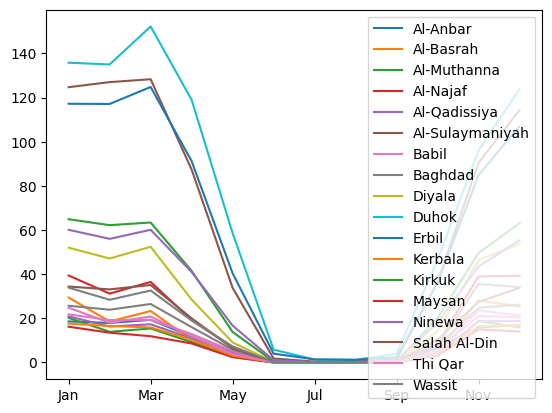

In [21]:
# =============================================================================
# VISUALISING MONTHLY RAINFALL
# =============================================================================

rain_month.plot()

To update the graphs following the hydrological year (Sep-Aug), reorder the index to start from September as illustrated below.

<Axes: >

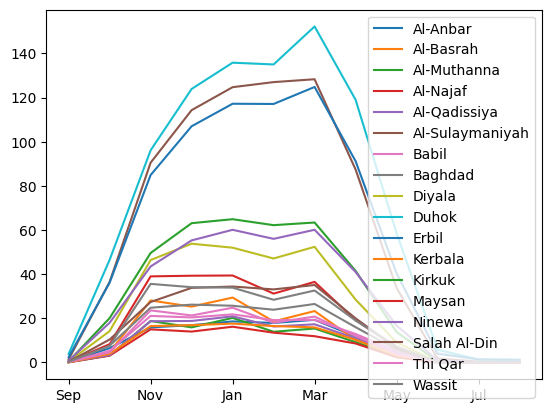

In [22]:
# =============================================================================
# VISUALISING MONTHLY RAINFALL FOR HYDROLOGICAL YEAR
# =============================================================================

# Reorder months to start from September
month_order_sept_aug = ['Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug']
rain_month = rain_month.reindex(month_order_sept_aug)
month_names = month_order_sept_aug

rain_month.plot()


To plot the data for only one governorate (e.g. Erbil), select the column of the dataframe as illustrated below. You can add the data of other colums, separated using a comma, try this out by adding Baghdad.

<Axes: >

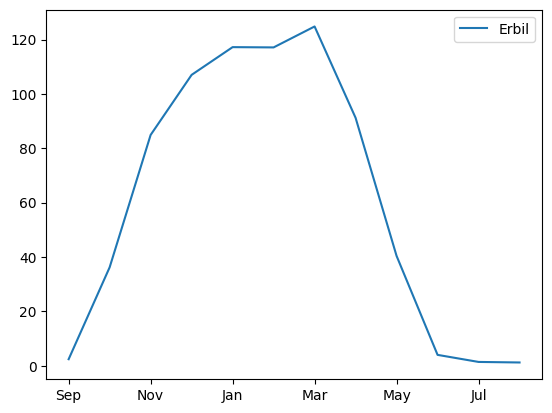

In [23]:
# =============================================================================
# VISUALISING MONTHLY RAINFALL FOR ONE STATION
# =============================================================================

rain_month[["Erbil"]].plot()

To change the graph to a bar chart add the following information `kind='bar'`

<Axes: >

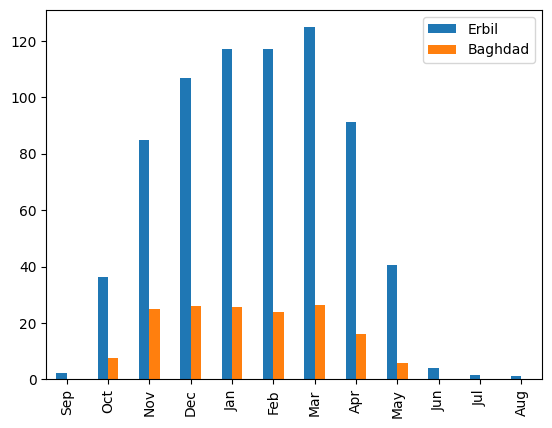

In [24]:
# =============================================================================
# VISUALISING MONTHLY RAINFALL USING BAR CHART
# =============================================================================

rain_month[["Erbil", "Baghdad"]].plot(kind='bar')

### 🔔 Quiz question:

Repeat the analyses for the Reference ET data and answer the following questions:
- Which month has the highest RET?
- Which governorate has the highest RET in that month and how much is it?

Note down your answers you need them for the MOOC Quiz!

In [26]:
# ============================================================
# MONTHLY VARIABILITY - REFERENCE ET
# ============================================================

import pandas as pd

# Ensure Date is datetime
df_ret["Date"] = pd.to_datetime(df_ret["Date"])

# Extract month
df_ret["Month"] = df_ret["Date"].dt.month

# Identify governorate columns
governorates = [
    col for col in df_ret.columns
    if col not in ["Date", "Month"]
]

# Compute monthly climatology for all governorates
ret_monthly = df_ret.groupby("Month")[governorates].mean()

# Display results
display(ret_monthly.round(2))

,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
Month,,,,,,,,,,,,,,,,,,
1,55.24,75.14,76.76,69.64,71.01,33.76,64.39,53.86,50.22,26.42,30.73,59.46,40.18,60.35,33.59,43.78,72.42,61.40
2,76.92,102.38,103.45,94.81,97.90,44.73,89.29,77.04,69.45,36.29,41.94,82.57,54.81,86.15,49.54,63.83,100.82,86.14
3,135.75,168.86,171.37,162.34,167.09,80.14,154.20,137.06,127.36,65.51,75.96,144.64,100.70,153.67,94.08,119.71,169.90,153.79
4,193.42,232.73,228.80,218.22,227.81,120.54,212.55,194.84,189.61,101.31,116.90,200.94,154.74,223.50,148.12,181.35,234.12,221.38
5,260.22,314.55,299.03,284.53,303.90,176.59,284.54,265.38,267.95,150.47,173.22,270.49,226.61,317.22,220.93,259.95,316.05,306.52
6,308.13,394.16,350.23,321.56,369.85,218.43,343.74,321.92,324.37,191.87,214.85,323.08,273.08,407.64,276.24,319.40,397.10,385.44
7,339.71,413.68,373.88,346.01,395.86,237.79,369.53,348.18,347.64,210.44,233.75,350.86,295.05,428.78,302.42,351.63,422.63,413.07
8,303.00,376.18,340.68,312.27,363.12,219.17,338.56,318.82,322.19,190.21,212.94,319.07,270.41,391.90,271.97,320.98,387.64,382.58
9,225.86,292.19,262.25,241.86,275.89,165.67,256.02,239.04,247.63,140.06,158.74,239.34,203.01,303.67,199.80,237.18,295.80,294.64


In [27]:
# Calculate average RET across all governorates for each month
monthly_mean_ret = ret_monthly.mean(axis=1)

# Identify month with highest average RET
highest_ret_month = monthly_mean_ret.idxmax()

print("Month with the highest average RET:",
      pd.to_datetime(str(highest_ret_month), format="%m").strftime("%B"))

print("Average RET across governorates:",
      round(monthly_mean_ret.max(), 2), "mm/month")

Month with the highest average RET: July
Average RET across governorates: 343.38 mm/month


In [28]:
# Get RET values for the month with the highest average
ret_values = ret_monthly.loc[highest_ret_month]

# Identify highest governorate
highest_ret_governorate = ret_values.idxmax()
highest_ret_value = ret_values.max()

print("\nGovernorate with the highest RET in that month:",
      highest_ret_governorate)

print("Highest RET value:",
      round(highest_ret_value, 2), "mm/month")


Governorate with the highest RET in that month: Maysan
Highest RET value: 428.78 mm/month


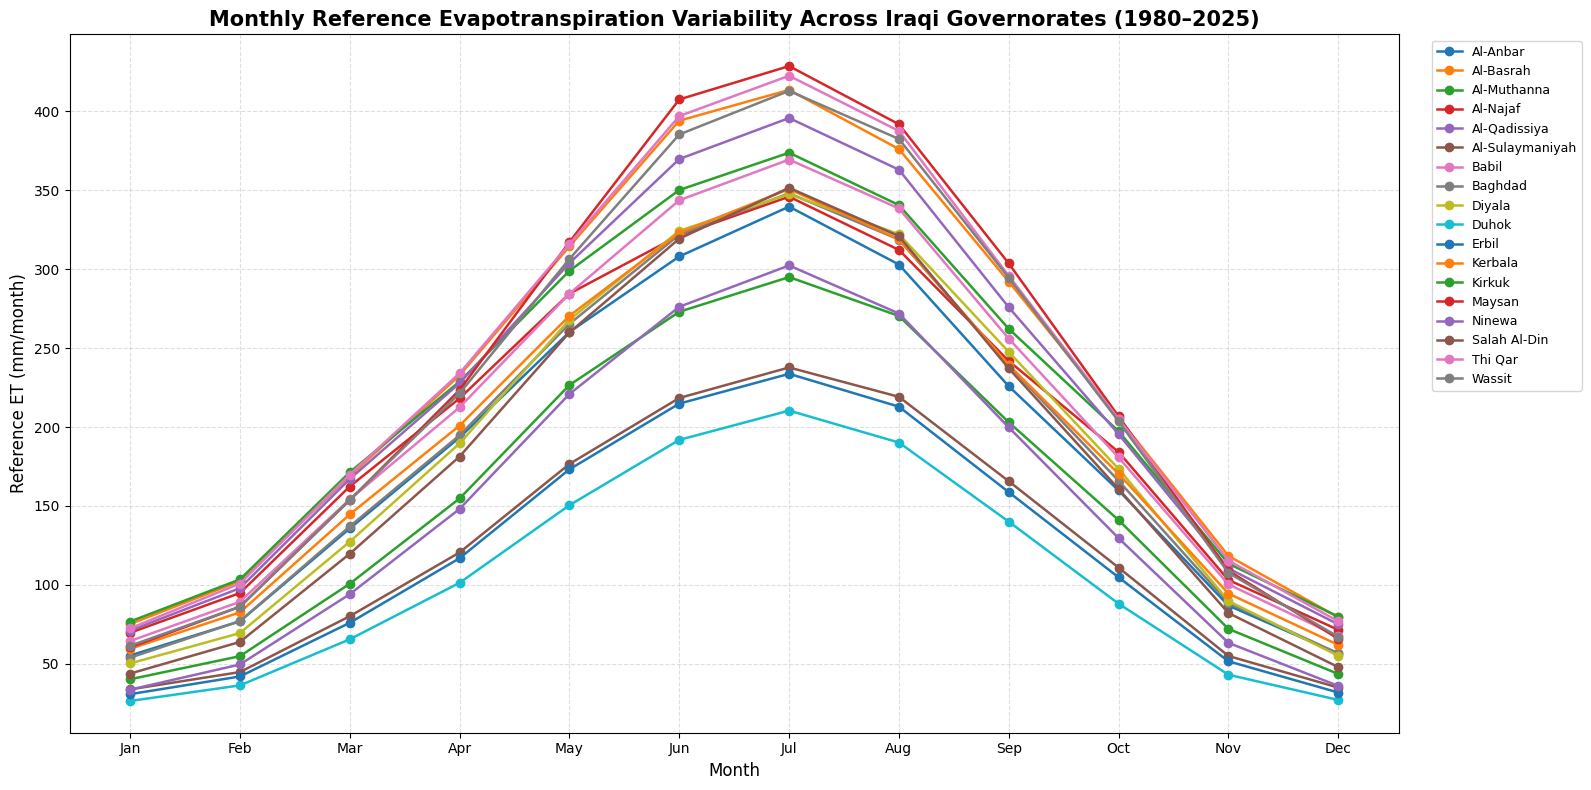

In [29]:
# =============================================================================
# VISUALISING MONTHLY RAINFALL
# =============================================================================
# ============================================================
# MONTHLY VARIABILITY OF REFERENCE ET
# ALL GOVERNORATES IN ONE GRAPH
# ============================================================

import matplotlib.pyplot as plt
import calendar

# Monthly climatology
ret_monthly = df_ret.groupby(
    df_ret["Date"].dt.month
)[governorates].mean()

# Create figure
plt.figure(figsize=(16, 8))

# Plot each governorate
for governorate in governorates:
    plt.plot(
        ret_monthly.index,
        ret_monthly[governorate],
        marker="o",
        linewidth=1.8,
        label=governorate
    )

# Configure x-axis
plt.xticks(
    range(1, 13),
    [calendar.month_abbr[m] for m in range(1, 13)]
)

plt.title(
    "Monthly Reference Evapotranspiration Variability "
    "Across Iraqi Governorates (1980–2025)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Reference ET (mm/month)", fontsize=12)

plt.grid(True, linestyle="--", alpha=0.4)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.show()


More visualisation options can be found in [Notebook 2.2 Visualising Timeseries Analyses](https://colab.research.google.com/github/wateraccounting/WaPOR4Global/blob/main/2_Long_Timeseries_Analyses/Notebook_2.2_Visualising_Timeseries_Analysis.ipynb?target="_blank")

---

## 5. Trend Analyses

We first plot the annual data for Erbil.

<Axes: xlabel='date'>

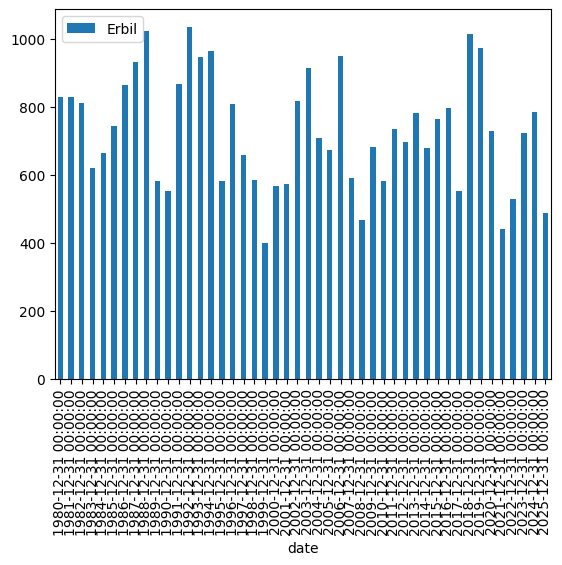

In [30]:
# =============================================================================
# VISUALISING ANNUAL RAINFALL USING BAR CHART
# =============================================================================

rain_annual[["Erbil"]].plot(kind='bar')

We apply the **Mann-Kendall test** — a robust non-parametric method for detecting monotonic trends in time series — to the annual totals of each governorate. The associated **Sen’s slope** tells us the rate of change (mm/year).

| Test | Purpose | Null Hypothesis |
|------|---------|-----------------|
| **Mann-Kendall** | Detect monotonic trend | No trend exists |
| **Sen’s Slope** | Estimate trend magnitude | — |

A **p-value < 0.05** indicates a statistically significant trend.

The following code cell creates the function to calculate the Mann-Kendall test.

In [31]:
# =============================================================================
# DEFINING FUNCTIONS FOR MANN-KENDALL TEST
# =============================================================================

def sens_slope(series):
    """Calculate Sen's slope estimate."""
    n = len(series)
    slopes = []
    values = series.values
    for i in range(n):
        for j in range(i + 1, n):
            slopes.append((values[j] - values[i]) / (j - i))
    return np.median(slopes)

def mann_kendall_test(series):
    """Perform Mann-Kendall trend test."""
    series_clean = series.dropna()
    if len(series_clean) < 10:
        return ('insufficient data', np.nan, np.nan)

    result = mk.original_test(series_clean)
    return (result.trend, result.p, result.slope)
    if p < 0.05:
        trend = 'increasing' if tau > 0 else 'decreasing'
    else:
        trend = 'no trend'
    return (trend, p, slope)


### Slope and significance
In the following code cell you evaluate the slope and significance for the annual rainfall.

In [32]:
# =============================================================================
# RUNNING MANN-KENDALL FUNCTION FOR RAINFALL
# =============================================================================

print("="*70)
print("RAINFALL TREND ANALYSIS (Annual Totals)")
print("="*70)

rain_trend_results = []
for gov in governorates:
    trend, p, slope = mann_kendall_test(rain_annual[gov])
    rain_trend_results.append({
        'Governorate': gov, 'Trend': trend,
        'p-value': round(p, 4), 'Slope (mm/yr)': round(slope, 2)
    })
rain_trend_df = pd.DataFrame(rain_trend_results).set_index('Governorate')
display(rain_trend_df.sort_values('Slope (mm/yr)'))

rain_sig = rain_trend_df[rain_trend_df['p-value'] < 0.05]
print(f"\n\U0001f4c8 Significant rainfall trends: {len(rain_sig)} / {n_gov}")

RAINFALL TREND ANALYSIS (Annual Totals)


,Trend,p-value,Slope (mm/yr)
Governorate,,,
Erbil,no trend,0.1611,-2.53
Duhok,no trend,0.3437,-2.53
Al-Sulaymaniyah,no trend,0.2045,-2.21
Ninewa,no trend,0.1205,-1.91
Kirkuk,no trend,0.3837,-1.31
Diyala,no trend,0.6770,-0.63
Salah Al-Din,no trend,0.4155,-0.53
Al-Qadissiya,no trend,0.4375,-0.30
Maysan,no trend,0.7909,-0.27



📈 Significant rainfall trends: 0 / 18


**📊 Exercise:** Repeat the steps for the reference ET data.

### 🔔Quiz questions:

How many stations have a significant trend in RET?
Which governorate has the largest rate of change (slope) and how much is this in mm/year (2 digits)?

*NOTE down your answers, you need them for the MOOC Quiz!*

In [33]:
# =============================================================================
# RUNNING MANN-KENDALL FUNCTION FOR RET
# =============================================================================
# ============================================================
# RUNNING MANN-KENDALL FUNCTION FOR RET
# ============================================================

import pymannkendall as mk
import pandas as pd

ret_trend_results = []

for governorate in ret_annual.columns:

    data = ret_annual[governorate].dropna()

    # Mann-Kendall trend test
    result = mk.original_test(data)

    ret_trend_results.append({
        "Governorate": governorate,
        "Trend": result.trend,
        "p-value": result.p,
        "Slope (mm/yr)": result.slope
    })

# Create results table
ret_trend_df = pd.DataFrame(ret_trend_results)

# Sort by slope
ret_trend_df = ret_trend_df.sort_values(
    "Slope (mm/yr)",
    ascending=False
)

ret_trend_df = ret_trend_df.set_index("Governorate")

print("=" * 70)
print("REFERENCE ET TREND ANALYSIS (ANNUAL TOTALS)")
print("=" * 70)

display(ret_trend_df.round(2))

# Count significant trends
significant_ret = ret_trend_df[
    ret_trend_df["p-value"] < 0.05
]

print("\nSignificant Reference ET trends:",
      len(significant_ret), "/", len(ret_trend_df))


REFERENCE ET TREND ANALYSIS (ANNUAL TOTALS)


,Trend,p-value,Slope (mm/yr)
Governorate,,,
Ninewa,increasing,0.00,3.82
Diyala,increasing,0.00,3.65
Kirkuk,increasing,0.00,3.36
Maysan,increasing,0.01,3.33
Wassit,increasing,0.02,3.05
Salah Al-Din,increasing,0.00,2.74
Erbil,increasing,0.00,2.69
Al-Muthanna,increasing,0.00,2.67
Al-Sulaymaniyah,increasing,0.00,2.62



Significant Reference ET trends: 13 / 18


In [34]:
# ============================================================
# QUIZ ANSWERS - REFERENCE ET
# ============================================================

print("Number of governorates with significant RET trends:",
      len(significant_ret))

if not significant_ret.empty:

    highest_slope = significant_ret["Slope (mm/yr)"].idxmax()

    slope_value = significant_ret.loc[
        highest_slope, "Slope (mm/yr)"
    ]

    print("Governorate with the highest significant slope:",
          highest_slope)

    print("Annual increase:",
          round(slope_value, 2), "mm/year per year")

else:
    print("No governorate has a statistically significant RET trend.")

Number of governorates with significant RET trends: 13
Governorate with the highest significant slope: Ninewa
Annual increase: 3.82 mm/year per year


### Visualising trend analyses results
Lets visualise these results in the graphs. To be able to visualise the results (trendline) together with the bar chart. As we are using two different chart types, we have to move from the standard `.plot` function and use the `matplotlib`.

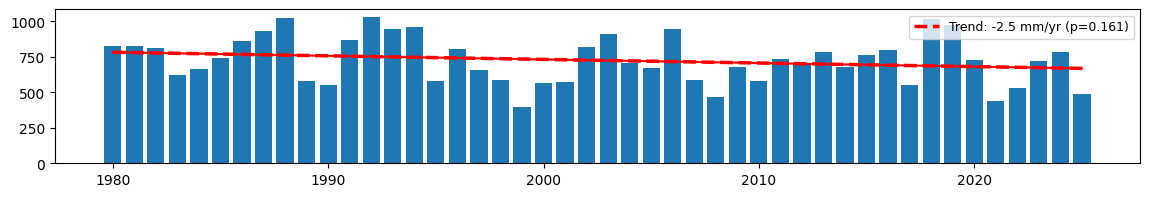

In [35]:
# =============================================================================
# TREND TIME SERIES - ANNUAL RAINFALL WITH FITTED LINE
# =============================================================================

# define the number of plots and figure size
fig, axes = plt.subplots(1, 1, figsize=(14,2))

# plot bar chart of the annual rainfall, define what to present on x-axis vs y-axis
years = rain_annual.index.year
values = rain_annual["Erbil"].values
axes.bar(years, values)

# define trend line equation
slope_val = rain_trend_df.loc["Erbil", 'Slope (mm/yr)']
p_val     = rain_trend_df.loc["Erbil", 'p-value']
x_num = np.arange(len(years))
intercept = np.median(values) - slope_val * np.median(x_num)
trend_line = intercept + slope_val * x_num

# add trend line to the plot in red
axes.plot(years,trend_line, color='red')

# to add equation to the chart uncomment the following two lines
axes.plot(years, trend_line, color='red', linewidth=2.5, linestyle='--', label=f"Trend: {slope_val:+.1f} mm/yr (p={p_val:.3f})")
axes.legend(fontsize=9, loc='upper right')

In [62]:
# Save figure
output_path = "/content/Erbil_Annual_Rainfall_Trend.png"

fig.savefig(
    output_path,
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

# Display figure
plt.show()

# Download figure
from google.colab import files
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **📊 Exercise:** Repeat the analyses for RET.

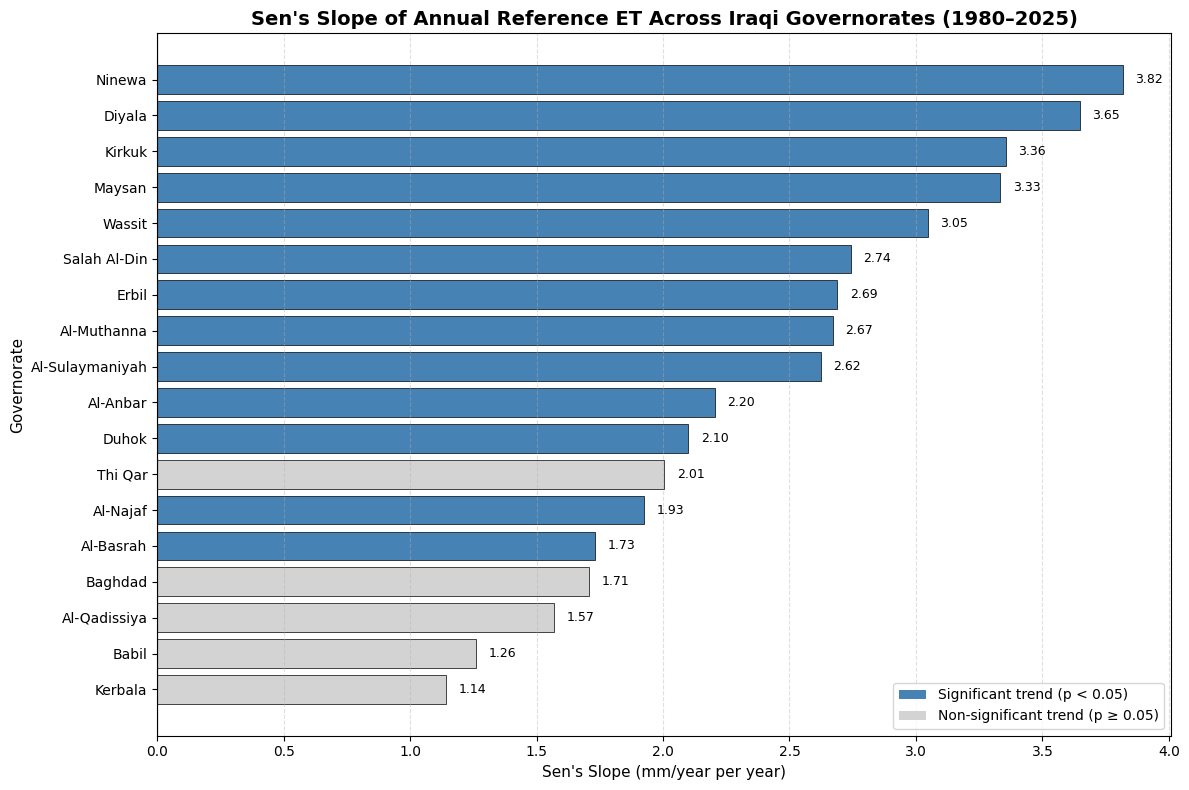

In [36]:
# ============================================================
# VISUALISATION OF REFERENCE ET TREND ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

# Prepare trend results
plot_data = ret_trend_df.copy()

# Identify statistically significant trends
plot_data["Significant"] = plot_data["p-value"] < 0.05

# Sort by Sen's slope
plot_data = plot_data.sort_values(
    by="Slope (mm/yr)",
    ascending=True
)

# Assign colours according to significance
colors = [
    "steelblue" if sig else "lightgray"
    for sig in plot_data["Significant"]
]

# Create horizontal bar chart
plt.figure(figsize=(12, 8))

bars = plt.barh(
    plot_data.index,
    plot_data["Slope (mm/yr)"],
    color=colors,
    edgecolor="black",
    linewidth=0.5
)

# Add slope values to bars
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}",
        va="center",
        fontsize=9
    )

# Add reference line
plt.axvline(0, color="black", linewidth=0.8)

# Chart formatting
plt.title(
    "Sen's Slope of Annual Reference ET Across Iraqi Governorates (1980–2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Sen's Slope (mm/year per year)",
    fontsize=11
)

plt.ylabel("Governorate", fontsize=11)

plt.grid(axis="x", linestyle="--", alpha=0.4)

# Legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="steelblue", label="Significant trend (p < 0.05)"),
    Patch(facecolor="lightgray", label="Non-significant trend (p ≥ 0.05)")
]

plt.legend(handles=legend_elements, loc="lower right")

plt.tight_layout()
plt.show()

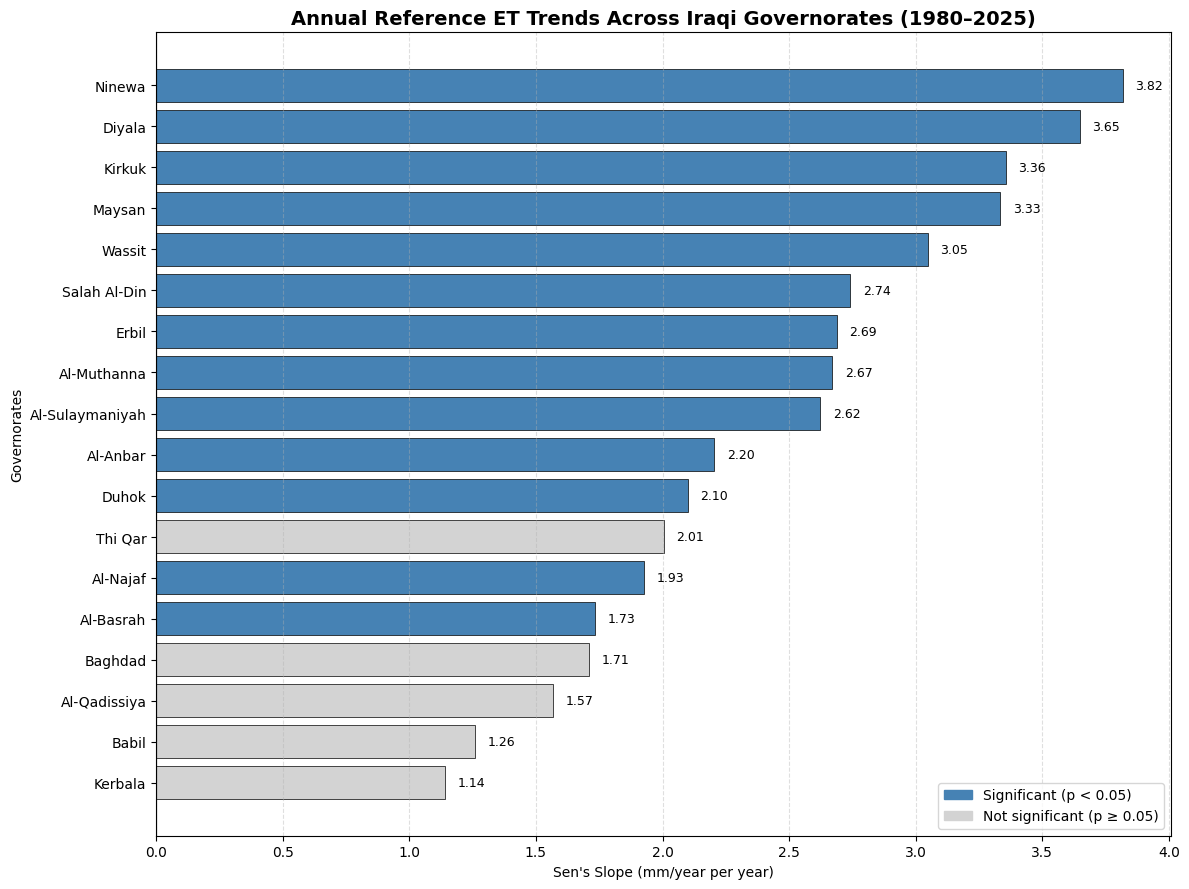

In [38]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Sort from highest to lowest slope
plot_data = ret_trend_df.sort_values(
    "Slope (mm/yr)",
    ascending=False
)

# Colour significant and non-significant trends
colors = [
    "steelblue" if p < 0.05 else "lightgray"
    for p in plot_data["p-value"]
]

plt.figure(figsize=(12, 9))

bars = plt.barh(
    plot_data.index,
    plot_data["Slope (mm/yr)"],
    color=colors,
    edgecolor="black",
    linewidth=0.5
)

# Put highest slope at the top
plt.gca().invert_yaxis()

# Add values
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}",
        va="center",
        fontsize=9
    )

plt.xlabel("Sen's Slope (mm/year per year)")
plt.ylabel("Governorates")

plt.title(
    "Annual Reference ET Trends Across Iraqi Governorates (1980–2025)",
    fontsize=14,
    fontweight="bold"
)

plt.axvline(0, color="black", linewidth=0.8)
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.legend(handles=[
    Patch(color="steelblue", label="Significant (p < 0.05)"),
    Patch(color="lightgray", label="Not significant (p ≥ 0.05)")
])

plt.tight_layout()
plt.show()

---
## 6. Anomalies

**Standardised anomalies** measure how unusual a year is compared to the long-term average:

$$Z_i = \frac{X_i - \bar{X}}{\sigma_X}$$

Where $X_i$ is the annual rainfall in year $i$, $\bar{X}$ is the long-term mean, and $\sigma_X$ is the standard deviation.

In [39]:
# =============================================================================
# CALCULATING STANDARDISED ANOMALY
# =============================================================================

# Compute standardised anomalies for annual rainfall
rain_anomaly = (rain_annual - rain_annual.mean()) / rain_annual.std()
print(rain_anomaly)


            Al-Anbar  Al-Basrah  Al-Muthanna  Al-Najaf  Al-Qadissiya  \
date                                                                   
1980-12-31  0.528741   0.153219     0.951229  0.893990      0.609969   
1981-12-31 -0.858511  -0.755189    -0.835166 -1.176963     -0.952619   
1982-12-31  2.036824   0.144079     0.167941  0.682473      0.233693   
1983-12-31 -0.397341  -0.984400    -0.757157  0.053748     -0.045101   
1984-12-31 -0.165748   0.565412     0.453880  0.115112      0.062440   
1985-12-31 -0.130362  -0.733920    -0.614767 -0.336377     -0.676939   
1986-12-31  0.113889   1.726058     1.910257  0.345484      1.122049   
1987-12-31 -0.485950  -0.825147    -0.574167 -0.858144      0.056692   
1988-12-31  2.442758  -1.036605    -0.920716  0.373938      0.197765   
1989-12-31 -0.657127  -0.017635    -0.075658 -0.057325      0.371413   
1990-12-31 -0.863114  -1.375149    -1.373405 -1.497839     -1.313327   
1991-12-31 -0.389573   0.707263     0.489550 -0.110804      0.83

Lets plot the results of Erbil in a bar chart.

In [ ]:
# =============================================================================
# ANNUAL ANOMALY BAR CHARTS - ERBIL
# =============================================================================
fig, axes = plt.subplots(1, 1, figsize=(16, 3))

years = rain_anomaly.index.year
values = rain_anomaly["Erbil"].values
axes.bar(years, values)

Lets calculate the most severe drought for each governorate.

In [40]:
# =============================================================================
# IDENTIFY THE MOST SEVERE DROUGHT
# =============================================================================

most_drought=rain_anomaly.min()
gov_most_drought=most_drought.idxmin()
print(most_drought)
print(gov_most_drought)


Al-Anbar          -1.986553
Al-Basrah         -1.651292
Al-Muthanna       -1.729814
Al-Najaf          -1.959270
Al-Qadissiya      -1.757625
Al-Sulaymaniyah   -2.093451
Babil             -1.864080
Baghdad           -1.719709
Diyala            -2.145032
Duhok             -1.981922
Erbil             -1.976955
Kerbala           -1.820131
Kirkuk            -1.936217
Maysan            -1.733474
Ninewa            -1.830078
Salah Al-Din      -2.005710
Thi Qar           -1.678065
Wassit            -1.981028
dtype: float64
Diyala


### Drought classification
Let's classify the results according to the five categories and give each category


| Z value | Classification |
|---------|---------------|
| Z ≤ −2.0 | **Extreme drought** |
| −2.0 < Z ≤ −1.0 | **Moderate drought** |
| −1.0 < Z < 1.0 | **Near normal** |
| 1.0 ≤ Z < 2.0 | **Moderately wet** |
| Z ≥ 2.0 | **Extremely wet** |

This reveals *when* droughts and wet periods hit Erbil hardest.
Lets calculate the number of droughts (Z < -1) for each governorate. Which governorate has the most droughts observed? How many times was an extreme drought (Z < -2) observed?  

In [41]:
# =============================================================================
# COUNT NUMBER OF DROUGHT YEARS
# =============================================================================
n_drought = (rain_anomaly < -2).sum()

print(n_drought)


Al-Anbar           0
Al-Basrah          0
Al-Muthanna        0
Al-Najaf           0
Al-Qadissiya       0
Al-Sulaymaniyah    1
Babil              0
Baghdad            0
Diyala             1
Duhok              0
Erbil              0
Kerbala            0
Kirkuk             0
Maysan             0
Ninewa             0
Salah Al-Din       1
Thi Qar            0
Wassit             0
dtype: int64


In [42]:
# =============================================================================
# COUNT NUMBER OF DROUGHT YEARS
# =============================================================================
all_drought = (rain_anomaly < -1).all(axis=1)
most_recent = rain_anomaly[all_drought].index.max()

print(most_recent)

2021-12-31 00:00:00


In [43]:
import pandas as pd

# Calculate Z-scores for annual precipitation
rain_z = (
    rain_annual - rain_annual.mean()
) / rain_annual.std()

print("ANNUAL PRECIPITATION Z-SCORES")
display(rain_z.round(2).tail(10))

ANNUAL PRECIPITATION Z-SCORES


,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
date,,,,,,,,,,,,,,,,,,
2016-12-31,-0.28,-0.60,-1.22,-0.22,-0.66,0.25,0.13,0.39,-0.18,0.64,0.41,0.11,0.07,-0.43,-0.03,0.01,-0.87,-0.24
2017-12-31,-0.98,-1.24,-1.30,-0.86,-0.97,-1.21,-0.79,-0.81,-0.90,-1.20,-1.05,-0.74,-1.16,-1.29,-1.14,-0.90,-1.10,-1.05
2018-12-31,2.73,2.20,2.74,3.12,2.58,1.90,2.98,3.65,3.11,1.63,1.72,3.98,2.29,2.60,1.68,3.04,3.44,2.75
2019-12-31,1.21,1.40,0.41,0.23,0.70,1.41,1.40,1.44,1.56,1.64,1.47,0.24,2.16,1.81,2.30,2.32,1.14,1.47
2020-12-31,-0.03,0.96,0.41,-0.07,0.16,0.21,0.45,0.42,0.30,0.07,0.00,0.15,-0.02,1.13,0.33,0.34,1.00,0.45
2021-12-31,-1.99,-1.65,-1.73,-1.96,-1.76,-2.09,-1.86,-1.72,-2.15,-1.63,-1.73,-1.82,-1.94,-1.73,-1.82,-2.01,-1.68,-1.98
2022-12-31,-0.75,-0.48,-0.53,-1.15,-1.22,-1.23,-1.22,-0.85,-1.22,-1.17,-1.20,-1.04,-1.12,-1.06,-1.10,-1.07,-0.74,-1.22
2023-12-31,0.20,0.69,0.84,1.23,0.86,0.20,0.81,0.71,0.55,0.40,-0.03,0.79,0.29,0.64,-0.31,0.64,0.93,0.67
2024-12-31,0.13,0.34,0.27,0.93,-0.14,0.55,0.07,0.72,1.26,0.77,0.33,0.36,0.37,0.40,0.02,0.62,0.09,0.11


In [44]:
# Identify years when all 18 governorates had Z < -1
all_governorates_drought = (rain_z < -1).all(axis=1)

drought_years = rain_z.index[all_governorates_drought]

print("Years when all 18 governorates experienced drought:")
print(drought_years.tolist())

if len(drought_years) > 0:
    print("\nMost recent drought year:", drought_years.max())
else:
    print("\nNo year recorded Z < -1 across all 18 governorates.")

Years when all 18 governorates experienced drought:
[Timestamp('2021-12-31 00:00:00')]

Most recent drought year: 2021-12-31 00:00:00


Can you also count the number of years which were moderately or extremely wet?

In [ ]:
# =============================================================================
# Count wet years
# =============================================================================



**📊 Exercise** Repeat the analyses for RET

---

## 7.  Aridity Index

The **UNEP Aridity Index** combines both rainfall and reference ET into a single metric:

$$AI = \frac{P}{ET_0}$$


Let's calculated the aridity index for each governorate using the mean annual Precipitation value divided by the mean annual reference ET value.

### Aridity classification
Let's classify the results according to the five categories and give each category

| Aridity Index | Classification | Character |
|:---:|---|---|
| AI < 0.03 | **Hyper-arid** | Desert; virtually no vegetation |
| 0.03 – 0.20 | **Arid** | Very limited rain; irrigation essential |
| 0.20 – 0.50 | **Semi-arid** | Rainfed possible in good years |
| 0.50 – 0.65 | **Dry sub-humid** | Rainfed agriculture viable |
| > 0.65 | **Humid** | Adequate water supply |

In [48]:
# ============================================================
# ARIDITY INDEX CLASSIFICATION - IRAQ
# ============================================================

# Calculate long-term mean annual precipitation
mean_annual_rain = rain_annual.mean()

# Calculate long-term mean annual reference ET
mean_annual_ret = ret_annual.mean()

# Calculate Aridity Index
aridity_index = mean_annual_rain / mean_annual_ret

# Create results table
aridity_df = pd.DataFrame({
    "Mean_Annual_Precipitation": mean_annual_rain,
    "Mean_Annual_RET": mean_annual_ret,
    "Aridity_Index": aridity_index
})

display(aridity_df.round(4))

,Mean_Annual_Precipitation,Mean_Annual_RET,Aridity_Index
Al-Anbar,111.6513,2201.4030,0.0507
Al-Basrah,143.4733,2773.4650,0.0517
Al-Muthanna,99.2589,2597.0907,0.0382
Al-Najaf,84.8922,2410.0315,0.0352
Al-Qadissiya,111.1230,2653.3185,0.0419
Al-Sulaymaniyah,746.4372,1497.5574,0.4984
Babil,125.5800,2461.1917,0.0510
Baghdad,157.0107,2267.1991,0.0693
Diyala,304.1741,2264.8089,0.1343
Duhok,879.5200,1270.7543,0.6921


### Visualisation of Aridity index

Create a simple horizontal bar chart to visualise the aridity index per governorate using `barh`. Run the cell as it is first, then uncomment one step at a time and see what changes.

- **Step 1:**  Plain bars - A single colour for every governorate.
- **Step 2:.** Colour by class - Each bar takes the colour of its aridity class *(replaces Step 1)*.
- **Step 3:** Threshold lines - Draw the classification thresholds as vertical dashed lines.
- **Step 4:** Value labels - The exact index printed at the end of each bar.
- **Step 5:** Scaled height - Figure height adjusted to the number of governorates *(replaces the figure line)*  comment out this line: `fig, ax = plt.subplots(1, 1, figsize=(16, 6))`    


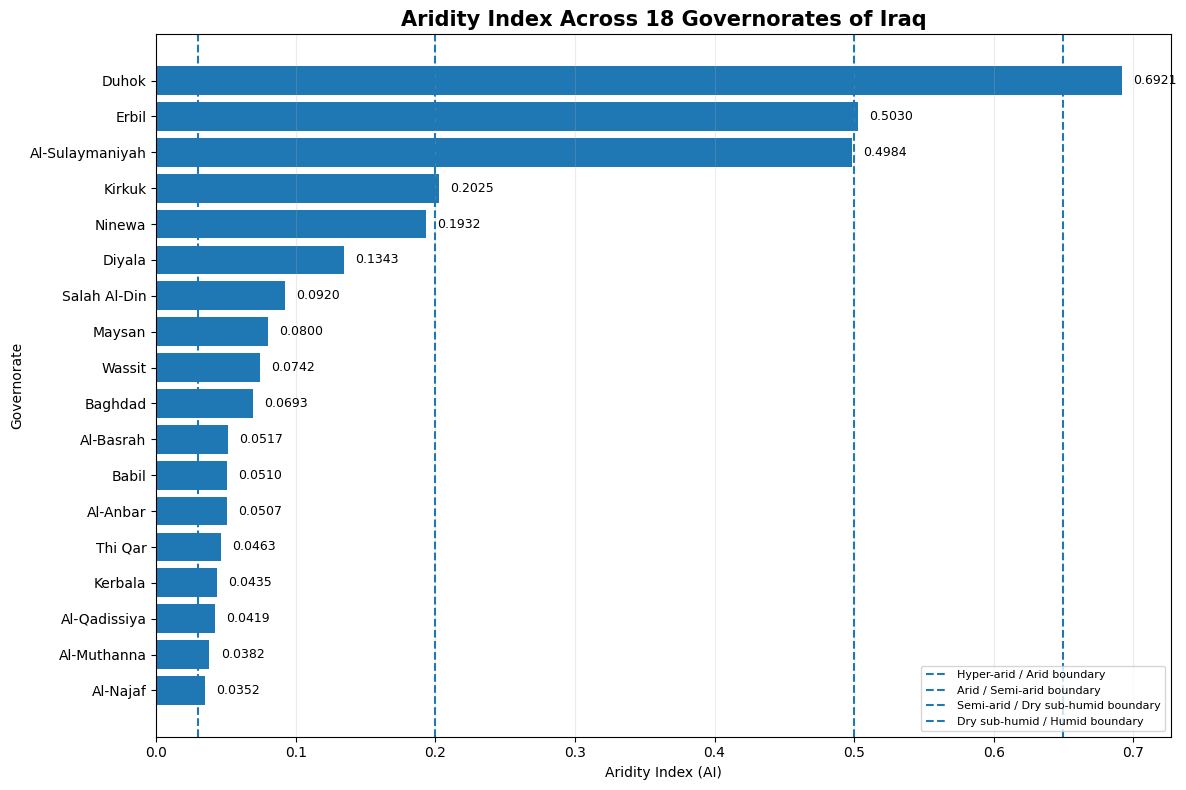

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Aridity Index data
aridity = {
    "Governorate": [
        "Al-Anbar", "Al-Basrah", "Al-Muthanna", "Al-Najaf",
        "Al-Qadissiya", "Al-Sulaymaniyah", "Babil", "Baghdad",
        "Diyala", "Duhok", "Erbil", "Kerbala", "Kirkuk",
        "Maysan", "Ninewa", "Salah Al-Din", "Thi Qar", "Wassit"
    ],

    "AI": [
        0.0507, 0.0517, 0.0382, 0.0352,
        0.0419, 0.4984, 0.0510, 0.0693,
        0.1343, 0.6921, 0.5030, 0.0435,
        0.2025, 0.0800, 0.1932, 0.0920,
        0.0463, 0.0742
    ]
}

df_aridity = pd.DataFrame(aridity)

# Sort by Aridity Index
df_aridity = df_aridity.sort_values("AI")

# Classify governorates
def classify_aridity(ai):
    if ai < 0.03:
        return "Hyper-arid"
    elif ai <= 0.20:
        return "Arid"
    elif ai <= 0.50:
        return "Semi-arid"
    elif ai <= 0.65:
        return "Dry sub-humid"
    else:
        return "Humid"

df_aridity["Class"] = df_aridity["AI"].apply(classify_aridity)

# Plot
fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    df_aridity["Governorate"],
    df_aridity["AI"]
)

# Classification threshold lines
ax.axvline(0.03, linestyle="--", linewidth=1.5,
           label="Hyper-arid / Arid boundary")

ax.axvline(0.20, linestyle="--", linewidth=1.5,
           label="Arid / Semi-arid boundary")

ax.axvline(0.50, linestyle="--", linewidth=1.5,
           label="Semi-arid / Dry sub-humid boundary")

ax.axvline(0.65, linestyle="--", linewidth=1.5,
           label="Dry sub-humid / Humid boundary")

# Add value labels
for bar, value in zip(bars, df_aridity["AI"]):
    ax.text(
        value + 0.008,
        bar.get_y() + bar.get_height()/2,
        f"{value:.4f}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Aridity Index Across 18 Governorates of Iraq",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Aridity Index (AI)")
ax.set_ylabel("Governorate")

ax.legend(
    loc="lower right",
    fontsize=8
)

ax.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    "/content/Iraq_Aridity_Index.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

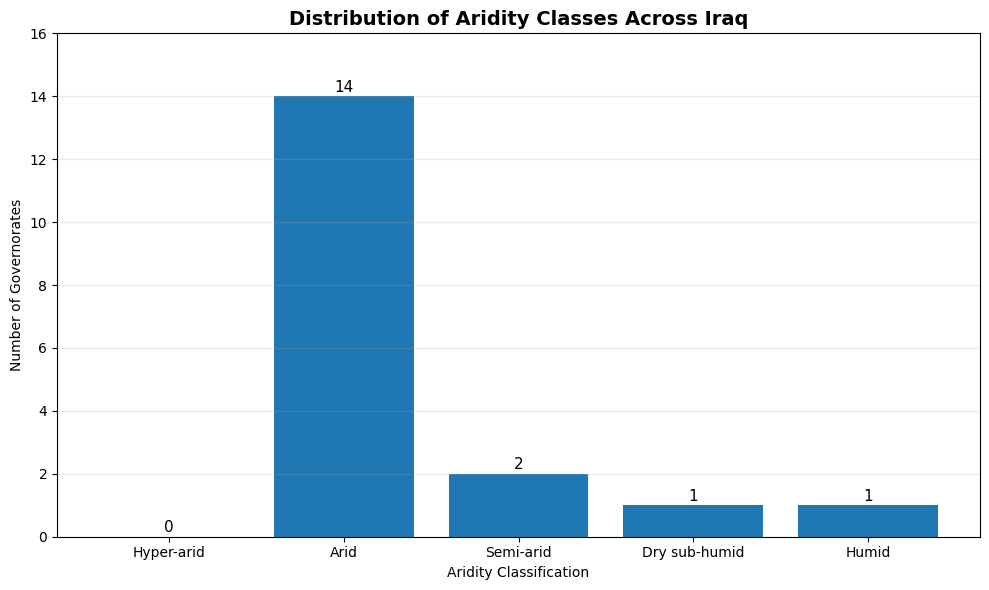

In [66]:
# Count governorates in each class
class_counts = df_aridity["Class"].value_counts()

class_order = [
    "Hyper-arid",
    "Arid",
    "Semi-arid",
    "Dry sub-humid",
    "Humid"
]

class_counts = class_counts.reindex(class_order, fill_value=0)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    class_counts.index,
    class_counts.values
)

# Add count labels
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.15,
        int(bar.get_height()),
        ha="center",
        fontsize=11
    )

ax.set_title(
    "Distribution of Aridity Classes Across Iraq",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Aridity Classification")
ax.set_ylabel("Number of Governorates")

ax.set_ylim(0, max(class_counts.values) + 2)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "/content/Iraq_Aridity_Classification.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

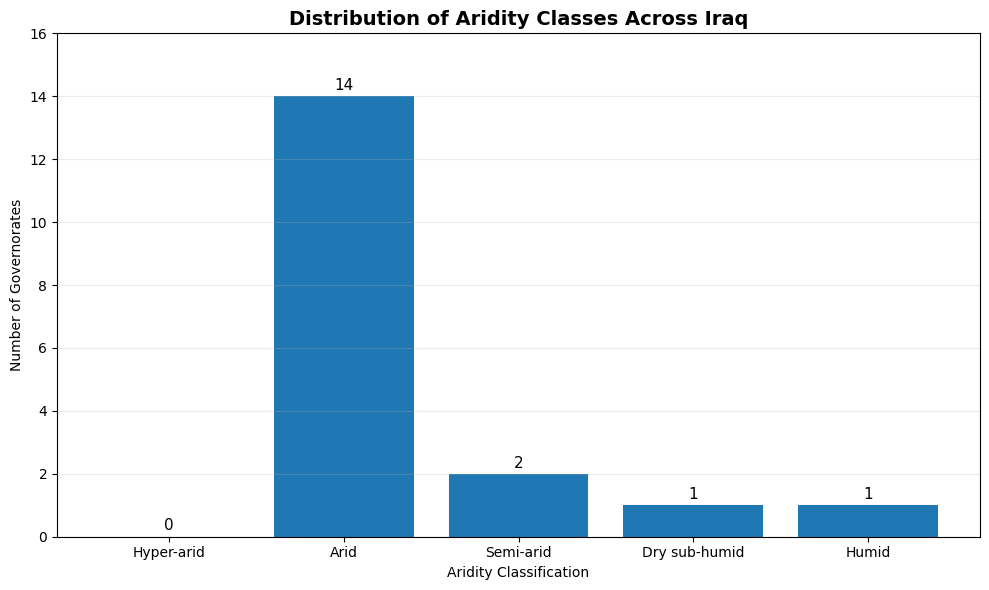

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [68]:
import matplotlib.pyplot as plt
from google.colab import files

# Classification counts
class_order = [
    "Hyper-arid",
    "Arid",
    "Semi-arid",
    "Dry sub-humid",
    "Humid"
]

class_counts = (
    df_aridity["Class"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    class_counts.index,
    class_counts.values
)

# Add values above bars
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f"{int(height)}",
        ha="center",
        fontsize=11
    )

# Chart details
ax.set_title(
    "Distribution of Aridity Classes Across Iraq",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Aridity Classification")
ax.set_ylabel("Number of Governorates")

ax.set_ylim(0, max(class_counts.values) + 2)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

# Save the exact figure BEFORE displaying it
output_path = "/content/Iraq_Aridity_Classification.png"

fig.savefig(
    output_path,
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

# Display
plt.show()

# Download
files.download(output_path)

plt.close(fig)

Lets create a summary of the different governorate found in each climatic zone.

In [ ]:
# =============================================================================
# SUMMARISING ARIDITY CLASSIFICATION
# =============================================================================

print("\U0001f4ca Aridity Classification Summary:")
print("-"*50)

def classify_aridity(ai):
    if ai < 0.03:  return 'Hyper-arid'
    elif ai < 0.20: return 'Arid'
    elif ai < 0.50: return 'Semi-arid'
    elif ai < 0.65: return 'Dry sub-humid'
    else:            return 'Humid'

ai_classes = pd.Series({g: classify_aridity(v) for g, v in ai_mean.items()})
for cls in ['Humid', 'Dry sub-humid', 'Semi-arid', 'Arid', 'Hyper-arid']:
    govs_in_class = ai_classes[ai_classes == cls].index.tolist()
    if govs_in_class:
        print(f"   {cls:15s}: {', '.join(govs_in_class)}")

---

## ➡️ 8. Visualising results

> Go to [Notebook 2.2 Visualising time series analyses](https://github.com/wateraccounting/WaPOR4Global/blob/main/2_Long_Time_Series_Analyses/Notebook_2.2_Visualising_Timeseries_Analyses.ipynb) to learn more about how to improve visualisation of the results. For this you have to save the data frames as csv files by using the following code. You need them to run the visualisation scripts!


In [63]:
# =============================================================================
# SAVING RESULTS
# =============================================================================

#saving results rainfall analyses
filepath = Path("/content/output_data/rain_annual.csv")
rain_annual.to_csv(filepath)
filepath = Path("/content/output_data/rain_stats.csv")
rain_stats.to_csv(filepath)
filepath = Path("/content/output_data/rain_month.csv")
rain_month.to_csv(filepath)
filepath = Path("/content/output_data/rain_trend.csv")
rain_trend_df.to_csv(filepath)

#saving results reference et analyses
filepath = Path("/content/output_data/ret_annual.csv")
ret_annual.to_csv(filepath)
filepath = Path("/content/output_data/ret_stats.csv")
ret_stats.to_csv(filepath)
filepath = Path("/content/output_data/ret_month.csv")
ret_month.to_csv(filepath)
filepath = Path("/content/output_data/ret_trend.csv")
ret_trend_df.to_csv(filepath)

#saving results aridity index
filepath = Path("/content/output_data/ai_mean.csv")
ai_mean.to_csv(filepath)

NameError: name 'ret_month' is not defined

In [ ]:

!zip -r /content/data.zip /content/output_data
from google.colab import files
files.download(r'/content/output_data_notebook_2.1.zip')

---

### 📚 References

1. **UNEP Aridity Index**: Middleton, N. & Thomas, D. (1997). World Atlas of Desertification.
2. **Mann-Kendall Test**: Mann, H.B. (1945). Nonparametric tests against trend. *Econometrica*, 13(3), 245–259.

---